# 01 — Data check and basic EDA

This notebook inspects one BEIR target-domain dataset before building retrieval models.

Default dataset: `beir/scifact/test`.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data.datasets import load_retrieval_dataset

In [2]:
DATASETS = [
    "beir/scifact/test",
    "beir/fiqa/test",
    "beir/nfcorpus/test",
]

In [5]:
DATASET_NAME = DATASETS[1]

dataset = load_retrieval_dataset(DATASET_NAME)

print(f"Dataset:   {DATASET_NAME}")
print(f"Documents: {len(dataset.documents):,}")
print(f"Queries:   {len(dataset.queries):,}")
print(f"Qrels:     {sum(len(v) for v in dataset.qrels.values()):,}")

[INFO] Opening /root/.ir_datasets/beir/fiqa/docs.pklz4/bin with direct file access


Dataset:   beir/fiqa/test
Documents: 57,638
Queries:   648
Qrels:     1,706


## Inspect a few examples

In [6]:
list(dataset.queries.items())[:5]

[('4641', 'Where should I park my rainy-day / emergency fund?'),
 ('5503',
  'Tax considerations for selling a property below appraised value to family?'),
 ('7803',
  'Can the Delta be used to calculate the option premium given a certain target?'),
 ('7017', 'Basic Algorithmic Trading Strategy'),
 ('10152',
  'What does a high operating margin but a small but positive ROE imply about a company?')]

In [7]:
list(dataset.documents.items())[:2]

[('3',
  "I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems in the U.S. (or their students) should worry a little about getting marketable skills in exchange for their massive investment in education, rather than getting out with thousands in student debt and then complaining that they aren't qualified to do anything."),
 ('31',
  "So nothing preventing false ratings besides additional scrutiny from the market/investors, but there are some newer controls in place to prevent institutions from using them. Under the DFA banks can no longer solely rely on credit ratings as due diligence to buy a financial instrument, so that's a plus. The intent being that if financial institutions do their own leg work then *maybe* they'll figure out that a certain CDO is garbage or not.  Edit: lead in")]

In [11]:
list(dataset.qrels.items())[:2]

[('8', {'566392': 1, '65404': 1}), ('15', {'325273': 1})]

In [12]:
len(list(dataset.qrels.items()))

648

## Convert to DataFrames

In [13]:
import pandas as pd

documents_df = pd.DataFrame(dataset.documents.items(), columns=["doc_id", "text"])
queries_df = pd.DataFrame(dataset.queries.items(), columns=["query_id", "query"])

qrel_rows = []
for query_id, rels in dataset.qrels.items():
    for doc_id, relevance in rels.items():
        qrel_rows.append({
            "query_id": query_id,
            "doc_id": doc_id,
            "relevance": relevance,
        })

qrels_df = pd.DataFrame(qrel_rows)

documents_df.head()

,doc_id,text
0,3,I'm not saying I don't like the idea of on-the...
1,31,So nothing preventing false ratings besides ad...
2,56,You can never use a health FSA for individual ...
3,59,Samsung created the LCD and other flat screen ...
4,63,Here are the SEC requirements: The federal sec...


In [14]:
queries_df.head()

,query_id,query
0,4641,Where should I park my rainy-day / emergency f...
1,5503,Tax considerations for selling a property belo...
2,7803,Can the Delta be used to calculate the option ...
3,7017,Basic Algorithmic Trading Strategy
4,10152,What does a high operating margin but a small ...


In [15]:
qrels_df.head()

,query_id,doc_id,relevance
0,8,566392,1
1,8,65404,1
2,15,325273,1
3,18,88124,1
4,26,285255,1


In [16]:
qrels_df['relevance'].unique()

array([1])

## Basic length statistics


In [23]:
documents_df["word_count"] = documents_df["text"].str.findall(r"\b\w+\b").str.len()
queries_df["word_count"] = queries_df["query"].str.findall(r"\b\w+\b").str.len()

print("Document length summary")
display(documents_df["word_count"].describe())

print("\nQuery length summary")
display(queries_df["word_count"].describe())

Document length summary


count    57638.000000
mean       138.477359
std        132.939750
min          0.000000
25%         59.000000
50%         95.000000
75%        169.000000
max       3056.000000
Name: word_count, dtype: float64


Query length summary


count    648.000000
mean      11.191358
std        4.389511
min        2.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       31.000000
Name: word_count, dtype: float64

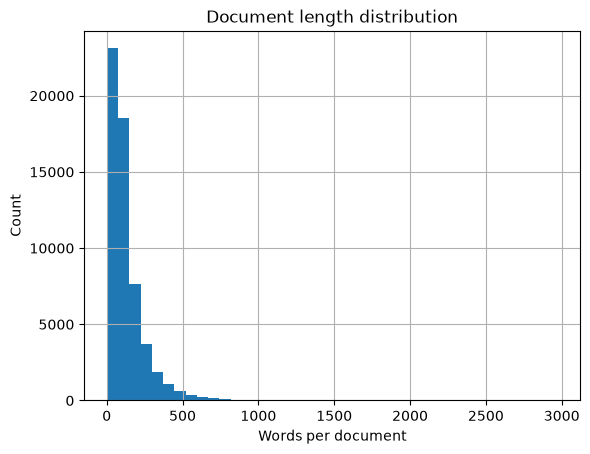

In [18]:
import matplotlib.pyplot as plt

documents_df["word_count"].hist(bins=40)
plt.title("Document length distribution")
plt.xlabel("Words per document")
plt.ylabel("Count")
plt.show()

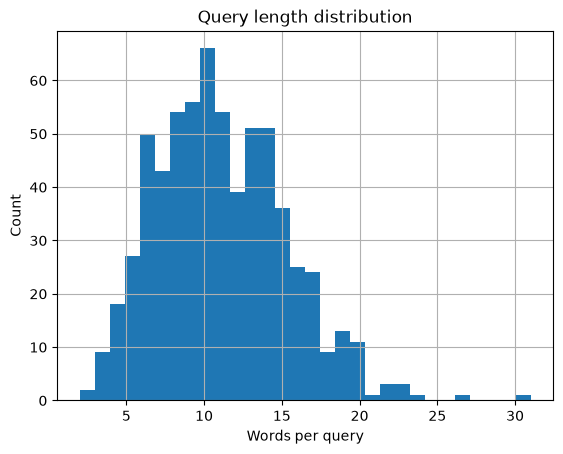

In [19]:
queries_df["word_count"].hist(bins=30)
plt.title("Query length distribution")
plt.xlabel("Words per query")
plt.ylabel("Count")
plt.show()

## Relevance-judgment structure

In [20]:
relevant_per_query = (
    qrels_df[qrels_df["relevance"] > 0]
    .groupby("query_id")
    .size()
)

In [21]:
relevant_per_query[relevant_per_query.sort_values(ascending=False) > 1].size

428

## Look at one query together with its relevant documents

In [24]:
example_query_id = next(
    query_id
    for query_id, rels in dataset.qrels.items()
    if any(rel > 0 for rel in rels.values())
)

print("Query ID:", example_query_id)
print("Query:", dataset.queries[example_query_id])
print()

for doc_id, relevance in dataset.qrels[example_query_id].items():
    if relevance > 0:
        print("Relevant document:", doc_id)
        print("Relevance:", relevance)
        print(dataset.documents[doc_id][:1200])
        print("-" * 80)

Query ID: 8
Query: How to deposit a cheque issued to an associate in my business into my business account?

Relevant document: 566392
Relevance: 1
Have the check reissued to the proper payee.
--------------------------------------------------------------------------------
Relevant document: 65404
Relevance: 1
Just have the associate sign the back and then deposit it.  It's called a third party cheque and is perfectly legal.  I wouldn't be surprised if it has a longer hold period and, as always, you don't get the money if the cheque doesn't clear. Now, you may have problems if it's a large amount or you're not very well known at the bank.  In that case you can have the associate go to the bank and endorse it in front of the teller with some ID.  You don't even technically have to be there.  Anybody can deposit money to your account if they have the account number. He could also just deposit it in his account and write a cheque to the business.
-------------------------------------------